# Da memória à atenção: RNNs, Encoder-Decoder e Transformers
### Notebook de demonstrações — Tópicos em IA e Otimização (PPGCC/UFLA)

**Fio condutor:** todas as demonstrações usam o mesmo problema — *prever as próximas 24 horas de uma série temporal a partir das últimas 72 horas*. Cada arquitetura resolve uma limitação da anterior.

| Demo | Pergunta | O que observar |
|---|---|---|
| **1** | Por que a RNN "esquece"? Como a LSTM resolve? | Gradiente ao longo do tempo e uma tarefa de memória longa |
| **2** | Como gerar uma *sequência* de saída? | Encoder-Decoder (Seq2Seq) prevendo 24 passos |
| **3** | O que é atenção, afinal? | Self-attention do zero, codificação posicional e um Transformer pequeno |

> **Na apresentação:** o notebook já está executado. Rode ao vivo apenas as células marcadas com ▶️ (rápidas). O notebook inteiro roda em ~2–3 min em CPU (Colab gratuito).

## 0. Configuração

In [1]:
import math, time
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))

# Estilo dos gráficos: fontes grandes para projeção
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 14, "axes.titlesize": 17, "axes.titleweight": "bold",
    "axes.labelsize": 15, "legend.fontsize": 13, "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "grid.linewidth": 0.8, "lines.linewidth": 2.2,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
})
# Cores fixas por modelo (as mesmas em todos os gráficos)
COR = {"real": "#0b0b0b", "rnn": "#eb6834", "lstm": "#2a78d6", "s2s": "#2a78d6",
       "tf": "#1baf7a", "pers": "#9a9890", "saz": "#eda100", "destaque": "#e34948"}

SALVAR = False          # True = salva as figuras em ./figuras (usado para montar os slides)
import os
if SALVAR: os.makedirs("figuras", exist_ok=True)
def mostrar(fig, nome):
    fig.tight_layout()
    if SALVAR: fig.savefig(f"figuras/{nome}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

## 1. Dados sintéticos — uma série "tipo vento"

Geramos uma série horária com três componentes que conhecemos de antemão — assim sabemos **o que** os modelos deveriam aprender:

$$y_t = \underbrace{8}_{\text{nível}} + \underbrace{2{,}5\,\sin\!\big(2\pi (t-9)/24\big)}_{\text{ciclo diário}} + \underbrace{s_t}_{\text{variação lenta (dias)}} + \underbrace{\varepsilon_t}_{\text{ruído AR(1)}}, \qquad \varepsilon_t = 0{,}9\,\varepsilon_{t-1} + \eta_t$$

* O **ciclo diário** (período 24 h) é o padrão que se repete — um bom modelo deve "olhar" para o mesmo horário do dia anterior.
* A **variação lenta** e o **ruído autocorrelacionado** tornam o problema não trivial.

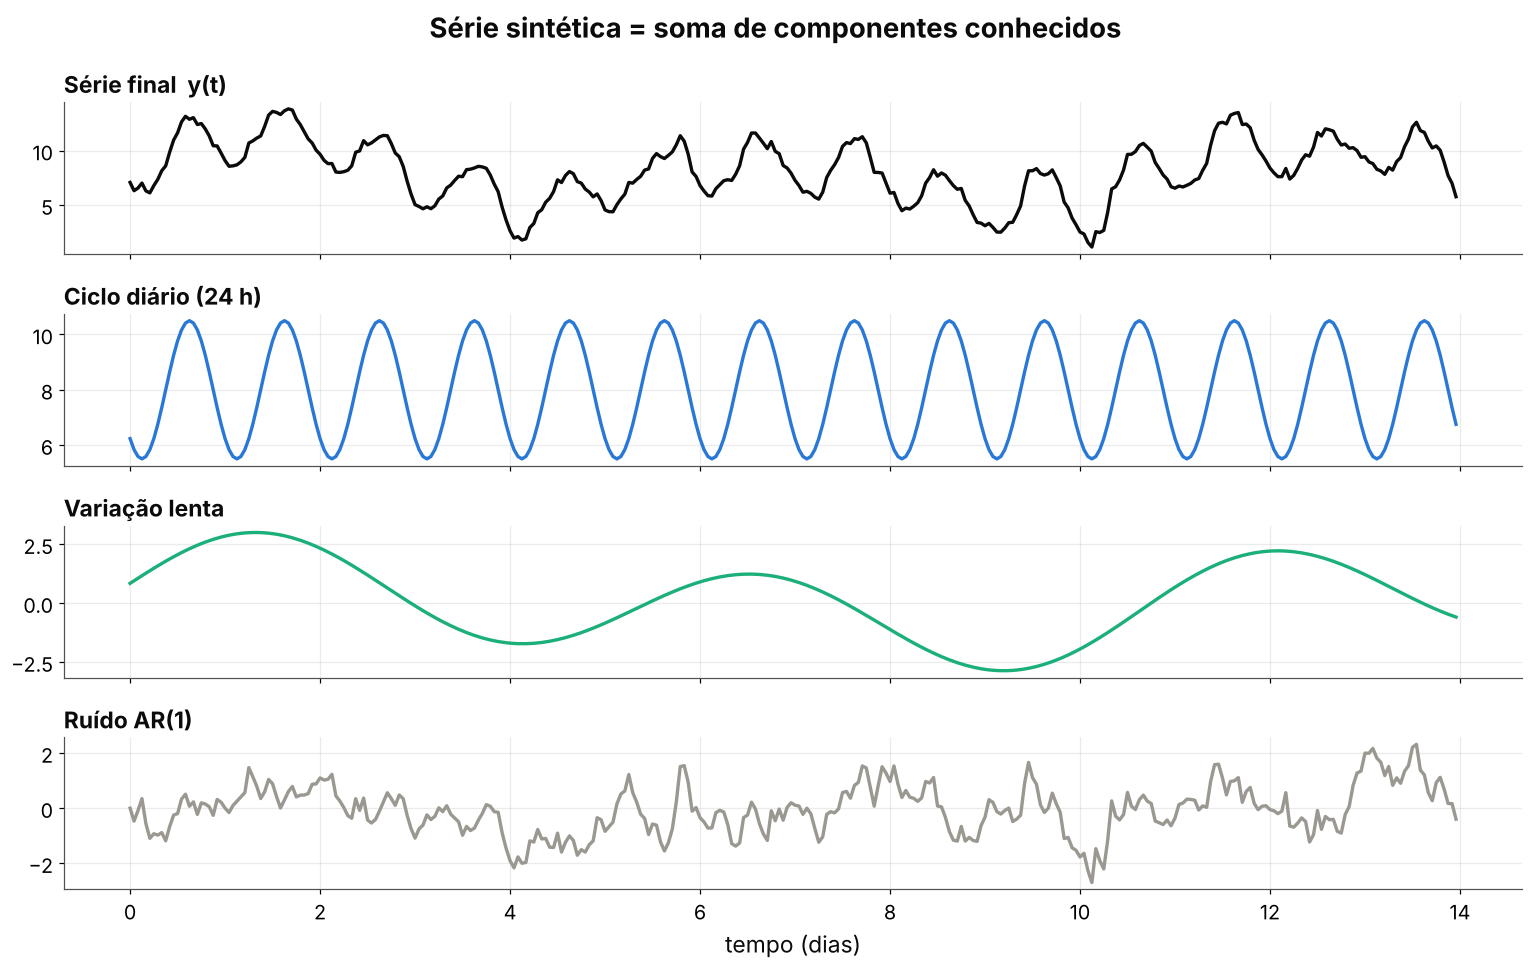

In [2]:
rng = np.random.default_rng(42)
N = 24 * 400                                   # 400 dias de dados horários
t = np.arange(N)
diario  = 2.5 * np.sin(2*np.pi*(t - 9)/24)
lento   = 2.0*np.sin(2*np.pi*t/(24*5.3)) + 1.0*np.sin(2*np.pi*t/(24*13.7) + 1)
ruido   = np.zeros(N); eta = rng.normal(0, 0.45, N)
for i in range(1, N): ruido[i] = 0.9*ruido[i-1] + eta[i]
y = np.clip(8 + diario + lento + ruido, 0, None)

# Normalização (estatísticas só do treino: 70% iniciais)
n_tr = int(0.70*N); n_te = int(0.85*N)
MU, SD = y[:n_tr].mean(), y[:n_tr].std()
z = (y - MU) / SD

fig, axs = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
janela = slice(0, 24*14)                      # 2 semanas
for ax, serie, nome, cor in zip(axs, [y, 8+diario, lento, ruido],
        ["Série final  y(t)", "Ciclo diário (24 h)", "Variação lenta", "Ruído AR(1)"],
        [COR["real"], COR["lstm"], COR["tf"], COR["pers"]]):
    ax.plot(t[janela]/24, serie[janela], color=cor)
    ax.set_title(nome, loc="left", fontsize=15)
axs[-1].set_xlabel("tempo (dias)")
fig.suptitle("Série sintética = soma de componentes conhecidos", fontsize=18, fontweight="bold")
mostrar(fig, "01_serie_componentes")

### O problema de previsão: 72 h de entrada → 24 h de saída

Cortamos a série em **janelas deslizantes**. Divisão **cronológica**: 70% treino · 15% (folga) · 15% teste.

Treino: (6624, 72)  |  Teste: (224, 72)


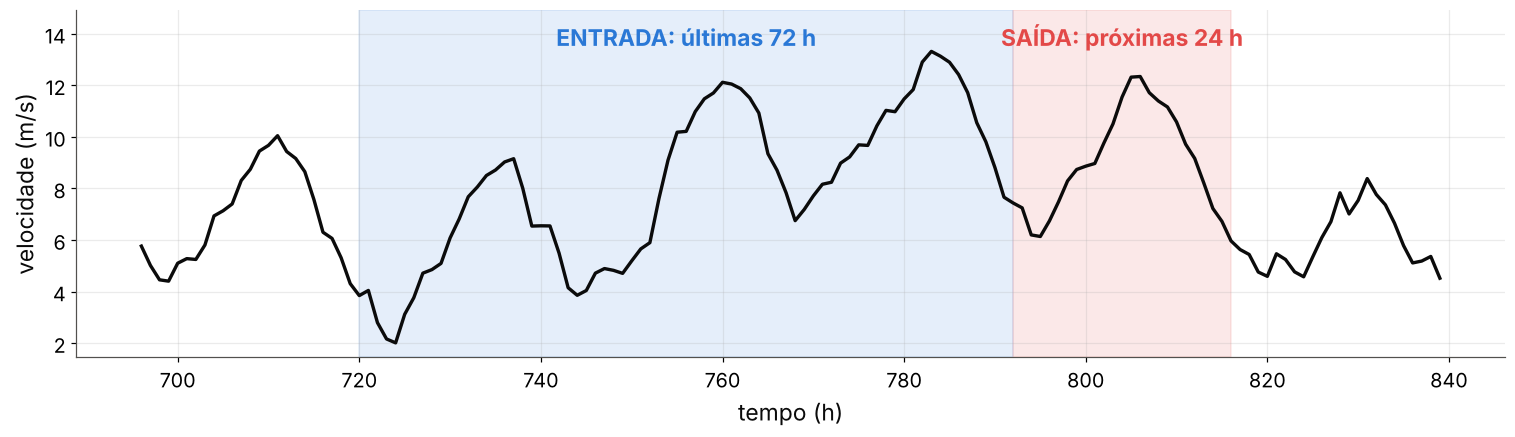

In [3]:
IN, OUT = 72, 24
def janelas(ini, fim, passo=1):
    idx = np.arange(ini, fim - IN - OUT, passo)
    X = np.stack([z[i:i+IN] for i in idx]); Y = np.stack([z[i+IN:i+IN+OUT] for i in idx])
    return torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)

Xtr, Ytr = janelas(0, n_tr)            # treino: todas as janelas
Xte, Yte = janelas(n_te, N, passo=6)   # teste: janelas a cada 6 h
print(f"Treino: {tuple(Xtr.shape)}  |  Teste: {tuple(Xte.shape)}")

i0 = 24*30
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(np.arange(i0-24, i0+IN+OUT+24), y[i0-24:i0+IN+OUT+24], color=COR["real"])
ax.axvspan(i0, i0+IN, color=COR["lstm"], alpha=0.12); ax.axvspan(i0+IN, i0+IN+OUT, color=COR["destaque"], alpha=0.12)
ytop = y[i0-24:i0+IN+OUT+24].max()
ax.text(i0+IN/2, ytop, "ENTRADA: últimas 72 h", ha="center", va="bottom", fontsize=15, color=COR["lstm"], fontweight="bold")
ax.text(i0+IN+OUT/2, ytop, "SAÍDA: próximas 24 h", ha="center", va="bottom", fontsize=15, color=COR["destaque"], fontweight="bold")
ax.set_xlabel("tempo (h)"); ax.set_ylabel("velocidade (m/s)")
ax.set_ylim(top=ytop*1.12)
mostrar(fig, "02_janela")

---
## 2. Demo 1 — RNN × LSTM: memória e gradiente

> 💡 **Analogia:** a RNN lê a série como você lê um livro: a cada página ($x_t$) atualiza o resumo da história que tem na cabeça ($h_t$), sem reler tudo. No treino, o sinal de erro volta como num **telefone sem fio** — e, a cada pessoa, se perde um pouco. A LSTM ganha um **caderno de anotações** ($c_t$) com **borracha** ($f_t$, o que apagar), **caneta** ($i_t$, quanto escrever), **rascunho** ($\tilde c_t$, o que escrever) e o que **ler em voz alta** ($o_t$, a saída).

**RNN simples** — o mesmo peso em todos os passos:
$$h_t = \tanh(W x_t + U h_{t-1} + b)$$

Ao treinar (BPTT), o gradiente que chega ao passo $k$ é um **produto** de Jacobianos:
$$\frac{\partial h_T}{\partial h_k} = \prod_{t=k+1}^{T} \underbrace{\operatorname{diag}\!\big(1-h_t^2\big)\,U}_{\text{tipicamente com norma} < 1} \;\Rightarrow\; \text{decai exponencialmente com } T-k$$

**LSTM** — a memória $c_t$ é atualizada de forma **aditiva**, controlada por portas ($\sigma$ = sigmoide, valores em $[0,1]$):
$$f_t=\sigma(\cdot),\quad i_t=\sigma(\cdot),\quad o_t=\sigma(\cdot),\quad \tilde c_t=\tanh(\cdot)$$
$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t, \qquad h_t = o_t \odot \tanh(c_t)$$
O caminho do gradiente pela memória é $\partial c_t/\partial c_{t-1} \approx f_t$: se a porta de esquecimento ficar perto de 1, o gradiente **atravessa o tempo sem desaparecer**.

### 2A ▶️ Quanto do gradiente chega a cada passo do passado?

> 💡 **Analogia:** telefone sem fio. Se cada pessoa repassa 90% do recado, depois de 99 pessoas sobra $0{,}9^{99} \approx 0{,}00003$. Na LSTM, o caderno é uma **via expressa**: o único “pedágio” entre um passo e outro é a borracha $f$ — se ela quase não apaga ($f \approx 1$), o recado chega.

Redes **não treinadas**, sequência de 100 passos. Medimos $\left\|\partial h_T / \partial x_t\right\|$ — "quanto a saída final é sensível à entrada no instante $t$".
Comparamos a RNN com duas LSTMs: porta de esquecimento inicializada "meio aberta" ($b_f=0 \Rightarrow f\approx0{,}5$) e "aberta" ($b_f=3 \Rightarrow f\approx0{,}95$).

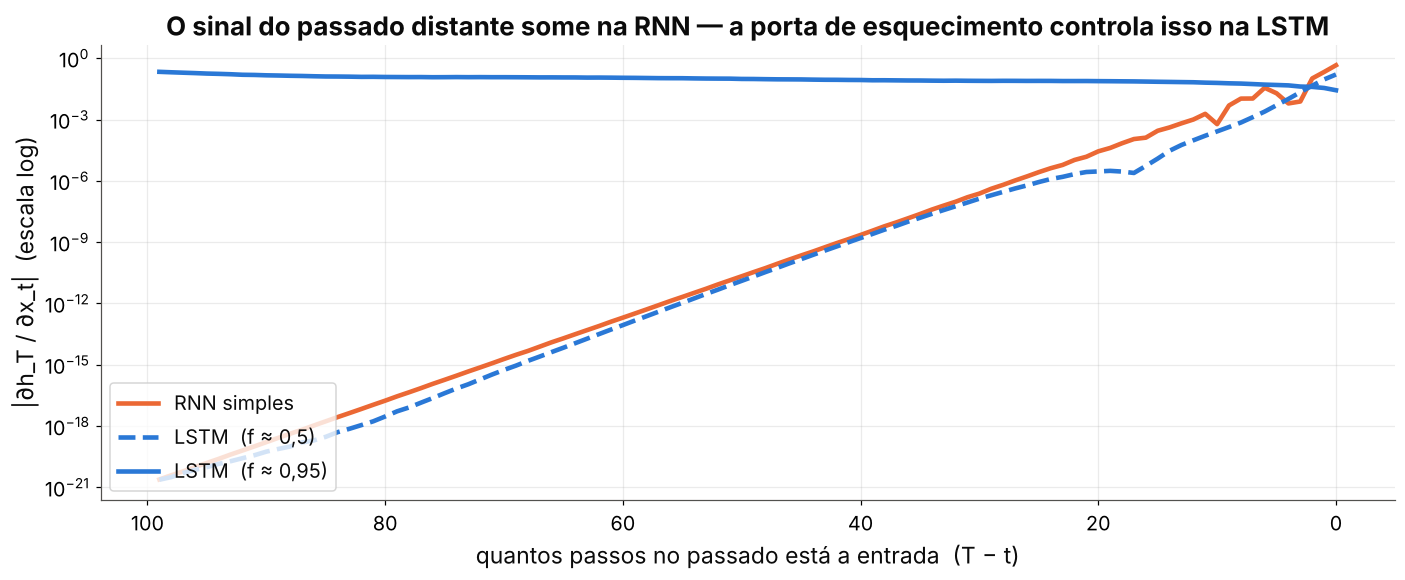

In [4]:
def lstm_com_bias_esquecimento(entrada, oculto, bf):
    m = nn.LSTM(entrada, oculto, batch_first=True)
    for nome, p in m.named_parameters():          # ordem das portas no PyTorch: i, f, g, o
        if "bias" in nome:
            p.data[oculto:2*oculto] = bf / 2      # bias_ih + bias_hh = bf
    return m

def sensibilidade(rede, T=100, H=64, reps=20):
    g = torch.zeros(T)
    for _ in range(reps):
        x = torch.randn(1, T, 1, requires_grad=True)
        h_seq = rede(x)[0]
        h_seq[0, -1].sum().backward()
        g += x.grad[0, :, 0].abs()
    return (g / reps).numpy()

torch.manual_seed(0)
H = 64
curvas = {
    "RNN simples": (sensibilidade(nn.RNN(1, H, batch_first=True)), COR["rnn"], "-"),
    "LSTM  (f ≈ 0,5)": (sensibilidade(lstm_com_bias_esquecimento(1, H, 0.0)), COR["lstm"], "--"),
    "LSTM  (f ≈ 0,95)": (sensibilidade(lstm_com_bias_esquecimento(1, H, 3.0)), COR["lstm"], "-"),
}
fig, ax = plt.subplots(figsize=(13, 5.5))
T = 100; passos_atras = T - 1 - np.arange(T)
for nome, (g, cor, ls) in curvas.items():
    ax.semilogy(passos_atras, g, color=cor, ls=ls, lw=3, label=nome)
ax.invert_xaxis()
ax.set_xlabel("quantos passos no passado está a entrada  (T − t)")
ax.set_ylabel("|∂h_T / ∂x_t|  (escala log)")
ax.set_title("O sinal do passado distante some na RNN — a porta de esquecimento controla isso na LSTM")
ax.legend(loc="lower left")
mostrar(fig, "03_gradiente_tempo")

**Leitura:** o eixo vertical é logarítmico. Na RNN, a sensibilidade cai várias ordens de grandeza em poucas dezenas de passos — o passado distante não consegue influenciar o aprendizado. Na LSTM, quanto mais aberta a porta de esquecimento, mais longe o gradiente chega. A rede **aprende** o valor de $f_t$ — por isso inicializar $b_f>0$ é uma prática comum (Jozefowicz et al., 2015).

### 2B. Tarefa de memória longa: "lembre o primeiro valor"

> 💡 **Analogia:** é como ouvir um ditado de 40 números e, no fim, responder qual foi o **primeiro**. Quem só lembra do que ouviu por último (a RNN) erra; quem anota no caderno e não apaga (a LSTM) acerta.

Cada sequência tem 40 valores aleatórios; o alvo é **o primeiro valor**. Os 39 seguintes são só distração. Para acertar, a rede precisa carregar uma informação por 40 passos.

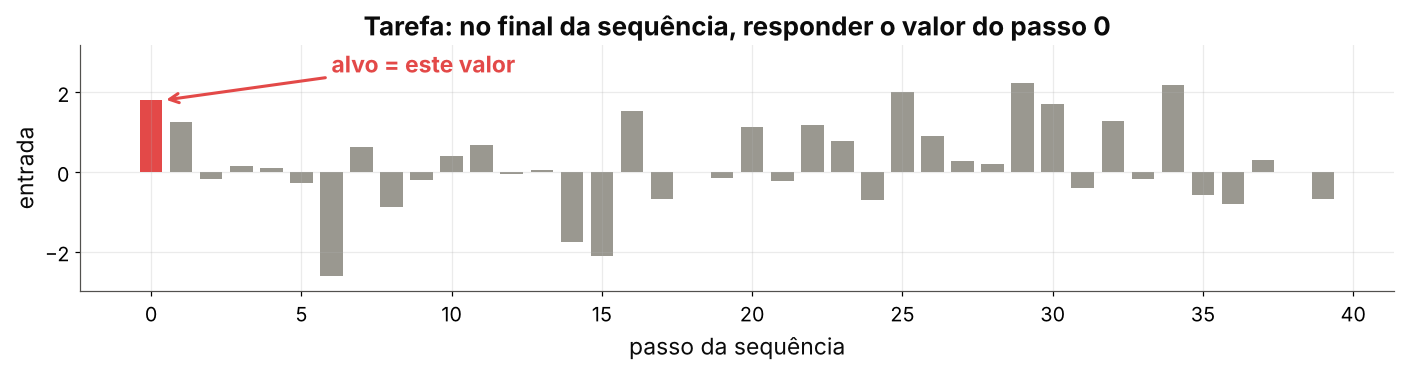

In [5]:
L = 40
def lote_memoria(B, L=L):
    x = torch.randn(B, L, 1)
    return x, x[:, 0, 0]

# Ilustração da tarefa
torch.manual_seed(4); x_ex, y_ex = lote_memoria(1)
x_ex[0, 0, 0] = 1.8   # valor de destaque, só para a ilustração
fig, ax = plt.subplots(figsize=(13, 3.6))
cores = [COR["destaque"]] + [COR["pers"]]*(L-1)
ax.bar(np.arange(L), x_ex[0, :, 0], color=cores, width=0.75)
ax.annotate("alvo = este valor", xy=(0.4, x_ex[0,0,0]), xytext=(6, 2.5), fontsize=15, color=COR["destaque"],
            fontweight="bold", arrowprops=dict(arrowstyle="->", color=COR["destaque"], lw=2))
ax.set_ylim(-3, 3.2); ax.set_xlabel("passo da sequência"); ax.set_ylabel("entrada")
ax.set_title("Tarefa: no final da sequência, responder o valor do passo 0")
mostrar(fig, "04_tarefa_memoria")

In [6]:
class Recorrente(nn.Module):
    def __init__(self, tipo, H=64):
        super().__init__()
        self.rnn = nn.RNN(1, H, batch_first=True) if tipo == "rnn" else lstm_com_bias_esquecimento(1, H, 3.0)
        self.saida = nn.Linear(H, 1)
    def forward(self, x):
        h_seq, _ = self.rnn(x)
        return self.saida(h_seq[:, -1]).squeeze(-1)   # usa só o último estado oculto

def treinar_memoria(tipo, iters=600, seed=0):
    torch.manual_seed(seed)
    m = Recorrente(tipo); opt = torch.optim.Adam(m.parameters(), 1e-2); hist = []
    for _ in range(iters):
        x, y = lote_memoria(128)
        loss = ((m(x) - y)**2).mean()
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
        hist.append(loss.item())
    return m, np.array(hist)

t0 = time.time()
mod_rnn,  hist_rnn  = treinar_memoria("rnn")
mod_lstm, hist_lstm = treinar_memoria("lstm")
print(f"Treino das duas redes: {time.time()-t0:.0f} s")

Treino das duas redes: 17 s


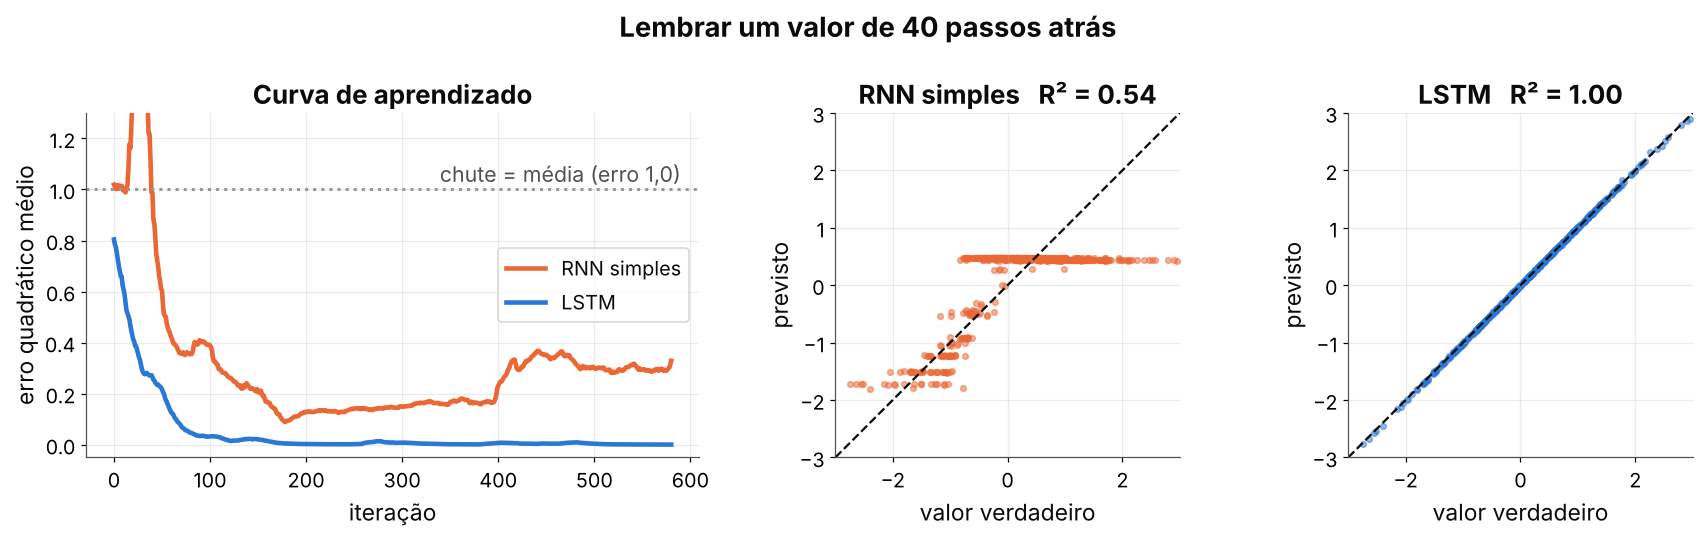

In [7]:
suav = lambda h, k=20: np.convolve(h, np.ones(k)/k, mode="valid")
torch.manual_seed(123); x_t, y_t = lote_memoria(500)
with torch.no_grad(): p_rnn, p_lstm = mod_rnn(x_t), mod_lstm(x_t)

fig, axs = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.5, 1, 1]})
axs[0].plot(suav(hist_rnn), color=COR["rnn"], lw=3, label="RNN simples")
axs[0].plot(suav(hist_lstm), color=COR["lstm"], lw=3, label="LSTM")
axs[0].axhline(1.0, color=COR["pers"], ls=":", lw=2); axs[0].text(590, 1.03, "chute = média (erro 1,0)", ha="right", color="#52514e")
axs[0].set_xlabel("iteração"); axs[0].set_ylabel("erro quadrático médio"); axs[0].set_title("Curva de aprendizado"); axs[0].legend()
axs[0].set_ylim(-0.05, 1.3)
for ax, p, nome, cor in [(axs[1], p_rnn, "RNN simples", COR["rnn"]), (axs[2], p_lstm, "LSTM", COR["lstm"])]:
    r2 = 1 - ((p - y_t)**2).mean() / y_t.var()
    ax.scatter(y_t, p, s=14, alpha=0.5, color=cor); ax.plot([-3, 3], [-3, 3], color=COR["real"], ls="--", lw=1.5)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
    ax.set_title(f"{nome}   R² = {r2:.2f}"); ax.set_xlabel("valor verdadeiro"); ax.set_ylabel("previsto")
fig.suptitle(f"Lembrar um valor de {L} passos atrás", fontsize=18, fontweight="bold")
mostrar(fig, "05_memoria_resultado")

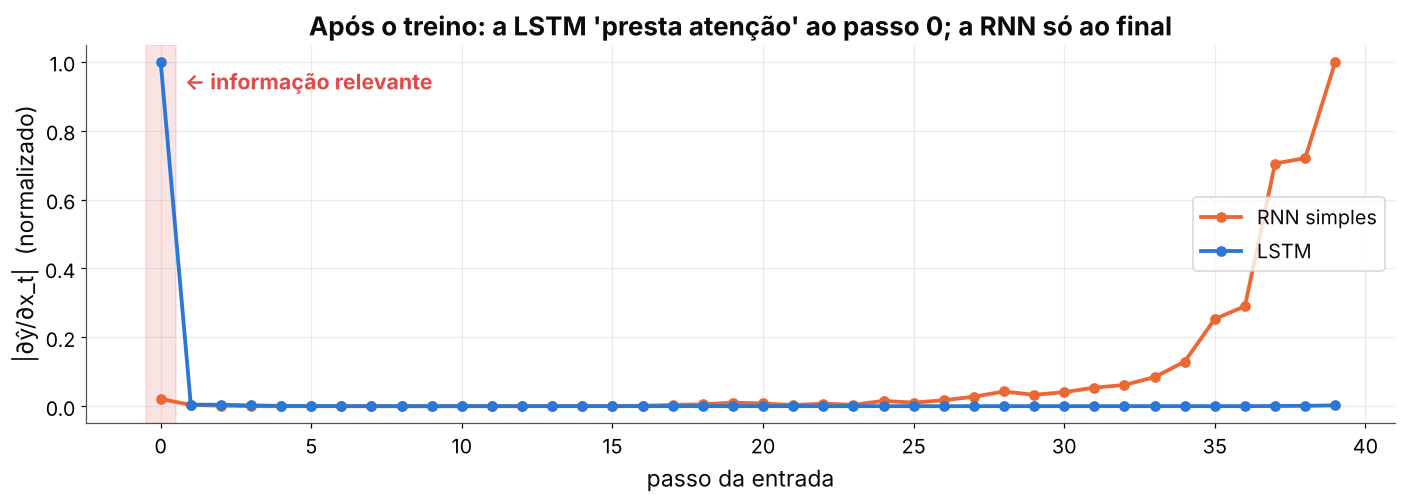

In [8]:
# Depois de treinadas: a quais entradas a resposta é sensível?
def sens_saida(m, reps=200):
    torch.manual_seed(7); x, _ = lote_memoria(reps); x.requires_grad_(True)
    m(x).abs().sum().backward()
    return x.grad[:, :, 0].abs().mean(0).numpy()
fig, ax = plt.subplots(figsize=(13, 4.8))
for m, nome, cor in [(mod_rnn, "RNN simples", COR["rnn"]), (mod_lstm, "LSTM", COR["lstm"])]:
    g = sens_saida(m); ax.plot(np.arange(L), g / g.max(), "o-", color=cor, lw=2.5, ms=6, label=nome)
ax.axvspan(-0.5, 0.5, color=COR["destaque"], alpha=0.15); ax.text(0.8, 0.92, "← informação relevante", color=COR["destaque"], fontsize=14, fontweight="bold")
ax.set_xlabel("passo da entrada"); ax.set_ylabel("|∂ŷ/∂x_t|  (normalizado)")
ax.set_title("Após o treino: a LSTM 'presta atenção' ao passo 0; a RNN só ao final")
ax.legend(loc="center right")
mostrar(fig, "06_sensibilidade_treinada")

**Mensagem da Demo 1:** a RNN simples só "enxerga" bem o passado recente. A LSTM aprende a **guardar** a informação relevante e a **ignorar** a distração — graças às portas e à atualização aditiva da memória.

---
## 3. Demo 2 — Encoder-Decoder (Seq2Seq): prever uma sequência

> 💡 **Analogia:** um **meteorologista de plantão**. Ele lê 3 dias de registros sem falar nada (encoder), forma uma impressão do tempo — anotada num **post-it** (o vetor de contexto) — e dita a previsão hora a hora (decoder), partindo do que acabou de dizer.

> 💡 **Teacher forcing = autoescola:** no treino, o instrutor endireita o volante ao fim de cada curva; na prova, sozinho, um erro leva ao próximo.

* **Encoder** (LSTM): lê as 72 h e resume tudo no estado final $(h, c)$ — o **vetor de contexto**.
* **Decoder** (LSTM): parte desse contexto e gera a saída **um passo por vez**, alimentando a própria previsão como entrada do passo seguinte (*autorregressivo*).

$$\underbrace{(h_0^{dec}, c_0^{dec})}_{\text{contexto}} = \text{Encoder}(x_1,\dots,x_{72}), \qquad \hat y_{k} = \text{Linear}\big(h_k^{dec}\big), \qquad h_k^{dec} = \text{LSTM}\big(\hat y_{k-1},\, h_{k-1}^{dec}\big)$$

**Teacher forcing:** no treino, o decoder recebe o valor **verdadeiro** $y_{k-1}$ em vez da própria previsão — treino mais rápido e estável. Na inferência não há valor verdadeiro, então ele usa $\hat y_{k-1}$ (os erros podem se acumular: *exposure bias*).

In [9]:
class Seq2Seq(nn.Module):
    def __init__(self, H=64):
        super().__init__()
        self.encoder = nn.LSTM(1, H, batch_first=True)
        self.decoder = nn.LSTMCell(1, H)
        self.saida = nn.Linear(H, 1)
    def forward(self, x, y_verdadeiro=None):
        _, (h, c) = self.encoder(x.unsqueeze(-1))     # contexto = estado final do encoder
        h, c = h[0], c[0]
        anterior = x[:, -1:]                          # último valor observado
        saidas = []
        for k in range(OUT):
            h, c = self.decoder(anterior, (h, c))
            y_k = self.saida(h); saidas.append(y_k)
            # teacher forcing (treino) ou autorregressivo (inferência)
            anterior = y_verdadeiro[:, k:k+1] if y_verdadeiro is not None else y_k
        return torch.cat(saidas, dim=1)

def treinar(modelo, epocas, teacher_forcing=False, lr=2e-3, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(modelo.parameters(), lr); n = len(Xtr); t0 = time.time()
    for ep in range(epocas):
        perm = torch.randperm(n)
        for i in range(0, n, 128):
            b = perm[i:i+128]; x, y = Xtr[b], Ytr[b]
            pred = modelo(x, y) if teacher_forcing else modelo(x)
            if isinstance(pred, tuple): pred = pred[0]
            loss = ((pred - y)**2).mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(modelo.parameters(), 1.0); opt.step()
    print(f"{type(modelo).__name__}: {epocas} épocas em {time.time()-t0:.0f} s")
    return modelo

n_par = lambda m: sum(p.numel() for p in m.parameters())
torch.manual_seed(0); s2s = Seq2Seq()
print(f"Parâmetros: {n_par(s2s):,}".replace(",", "."))
s2s = treinar(s2s, epocas=8, teacher_forcing=True)

Parâmetros: 34.369


Seq2Seq: 8 épocas em 11 s


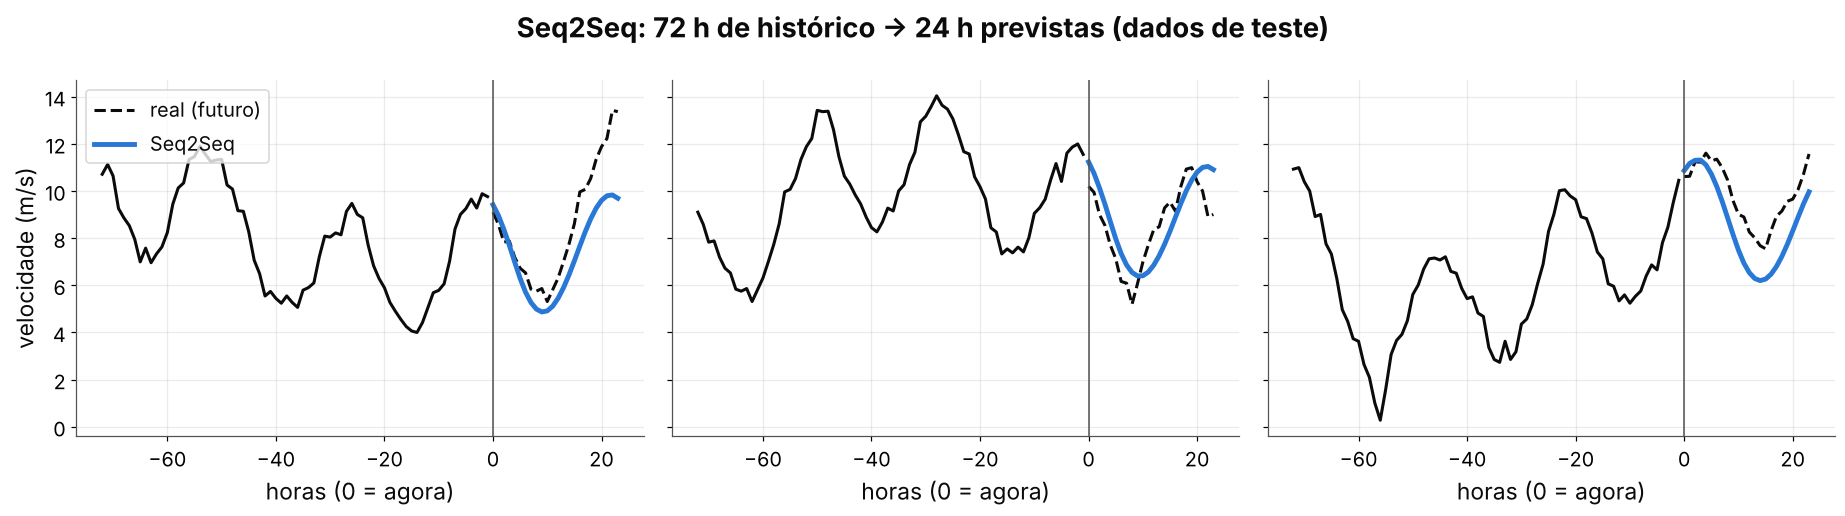

In [10]:
with torch.no_grad(): P_s2s = s2s(Xte)          # inferência autorregressiva
desn = lambda a: a.numpy()*SD + MU                # volta para m/s

# Referências simples (baselines)
P_pers = Xte[:, -1:].expand(-1, OUT)              # persistência: repete o último valor
P_saz  = Xte[:, -24:]                             # sazonal: repete as últimas 24 h
mae_h = lambda P: (P - Yte).abs().mean(0).numpy()*SD

fig, axs = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, j in zip(axs, [3, 15, 30]):
    tx = np.arange(-IN, 0); ty = np.arange(0, OUT)
    ax.plot(tx, desn(Xte[j]), color=COR["real"], lw=2)
    ax.plot(ty, desn(Yte[j]), color=COR["real"], lw=2, ls="--", label="real (futuro)")
    ax.plot(ty, desn(P_s2s[j]), color=COR["s2s"], lw=3.2, label="Seq2Seq")
    ax.axvline(0, color="#52514e", lw=1); ax.set_xlabel("horas (0 = agora)")
axs[0].set_ylabel("velocidade (m/s)"); axs[0].legend(loc="upper left")
fig.suptitle("Seq2Seq: 72 h de histórico → 24 h previstas (dados de teste)", fontsize=18, fontweight="bold")
mostrar(fig, "07_seq2seq_exemplos")

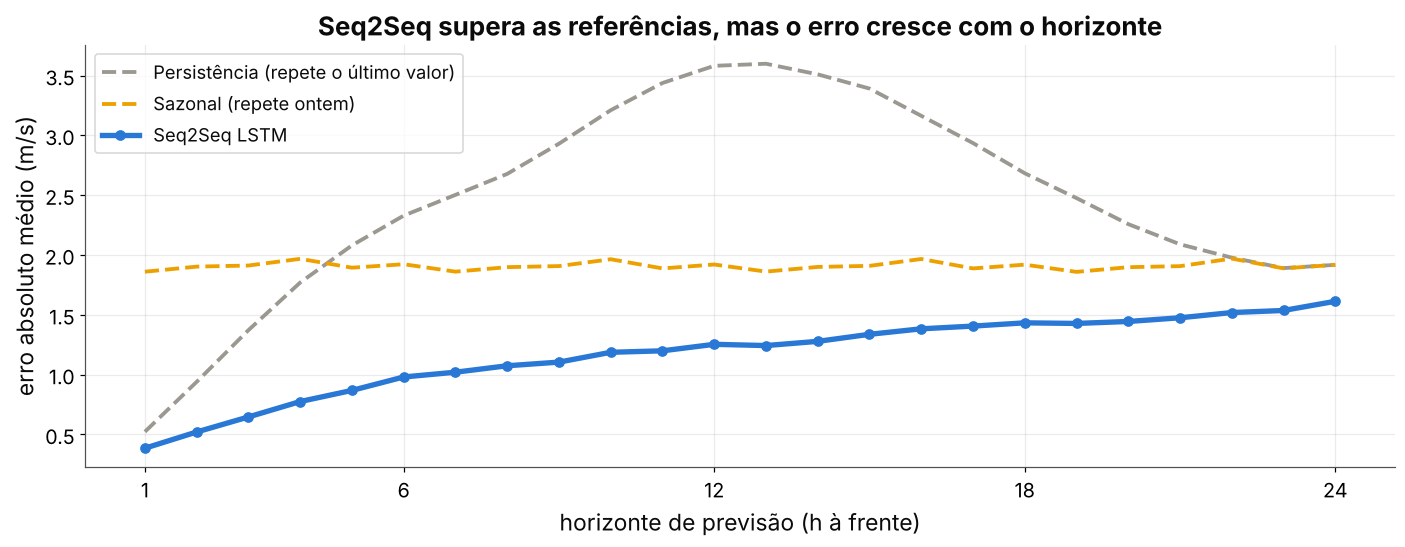

In [11]:
fig, ax = plt.subplots(figsize=(13, 5.2))
h = np.arange(1, OUT+1)
ax.plot(h, mae_h(P_pers), color=COR["pers"], lw=2.5, ls="--", label="Persistência (repete o último valor)")
ax.plot(h, mae_h(P_saz),  color=COR["saz"],  lw=2.5, ls="--", label="Sazonal (repete ontem)")
ax.plot(h, mae_h(P_s2s),  color=COR["s2s"],  lw=3.5, marker="o", ms=6, label="Seq2Seq LSTM")
ax.set_xlabel("horizonte de previsão (h à frente)"); ax.set_ylabel("erro absoluto médio (m/s)")
ax.set_title("Seq2Seq supera as referências, mas o erro cresce com o horizonte")
ax.legend(loc="upper left", fontsize=12); ax.set_xticks([1, 6, 12, 18, 24])
mostrar(fig, "08_seq2seq_mae")

**Mensagem da Demo 2:** o Seq2Seq supera as referências simples, mas toda a informação das 72 h precisa caber no **vetor de contexto** (64 números de $h$ e 64 de $c$). Esse é o **gargalo**: o decoder não pode "voltar" e consultar um instante específico da entrada. É exatamente isso que a **atenção** resolve.

---
## 4. Demo 3 — Atenção e Transformers

> 💡 **Analogia:** uma **pesquisa na biblioteca**. A **query** é a pergunta que você leva; a **key** é a etiqueta na lombada de cada livro; o **value** é o conteúdo. Em vez de levar um único livro (busca exata), você lê vários e mistura o que leu, com mais peso para os que mais combinam com a pergunta. Os quatro passos da fórmula: **notas de afinidade** ($QK^\top$) → **ajuste de escala** ($\div\sqrt{d_k}$) → **fatias de uma pizza** que somam 100% (softmax) → **mistura** dos conteúdos na proporção das fatias ($\times V$).

**Atenção = busca "suave" em um dicionário.** Cada elemento gera três vetores:
* **Query** $q$ — "o que estou procurando?"
* **Key** $k$ — "o que eu tenho para oferecer?" (usado para comparar)
* **Value** $v$ — "o conteúdo que eu entrego"

$$\text{Atenção}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

1. $QK^\top$: similaridade (produto escalar) de cada query com cada key → matriz de **scores**.
2. $/\sqrt{d_k}$: mantém os scores numa escala estável (ver 3B).
3. softmax por linha: transforma scores em **pesos** positivos que somam 1.
4. $\times V$: cada saída é uma **média ponderada** dos values.

Em **self-attention**, $Q$, $K$ e $V$ vêm da mesma sequência: $Q=XW_Q$, $K=XW_K$, $V=XW_V$.

### 3A ▶️ Self-attention do zero (a função inteira)

> 💡 **Analogia:** na RNN, a informação anda como num telefone sem fio; na self-attention é uma **reunião**: cada instante fala diretamente com qualquer outro, de uma vez.



In [12]:
def atencao(Q, K, V, mascara=None):
    # Q: (..., n_q, d)   K: (..., n_k, d)   V: (..., n_k, d_v)
    d_k = Q.shape[-1]
    scores = Q @ K.transpose(-2, -1) / math.sqrt(d_k)        # 1. similaridade (escalada)
    if mascara is not None:
        scores = scores.masked_fill(mascara, float("-inf"))   #    (opcional) bloqueia posições
    pesos = torch.softmax(scores, dim=-1)                     # 2. pesos: cada linha soma 1
    return pesos @ V, pesos                                   # 3. média ponderada dos values

**Exemplo interpretável (sem treino).** Cada instante de uma janela de 72 h é representado pela sua **hora do dia** $\big[\sin(2\pi\,\text{hora}/24),\ \cos(2\pi\,\text{hora}/24)\big]$. Usando $Q = K = 3\cdot$(esse vetor), a similaridade é alta entre instantes no **mesmo horário**. Os values são as próprias medições.

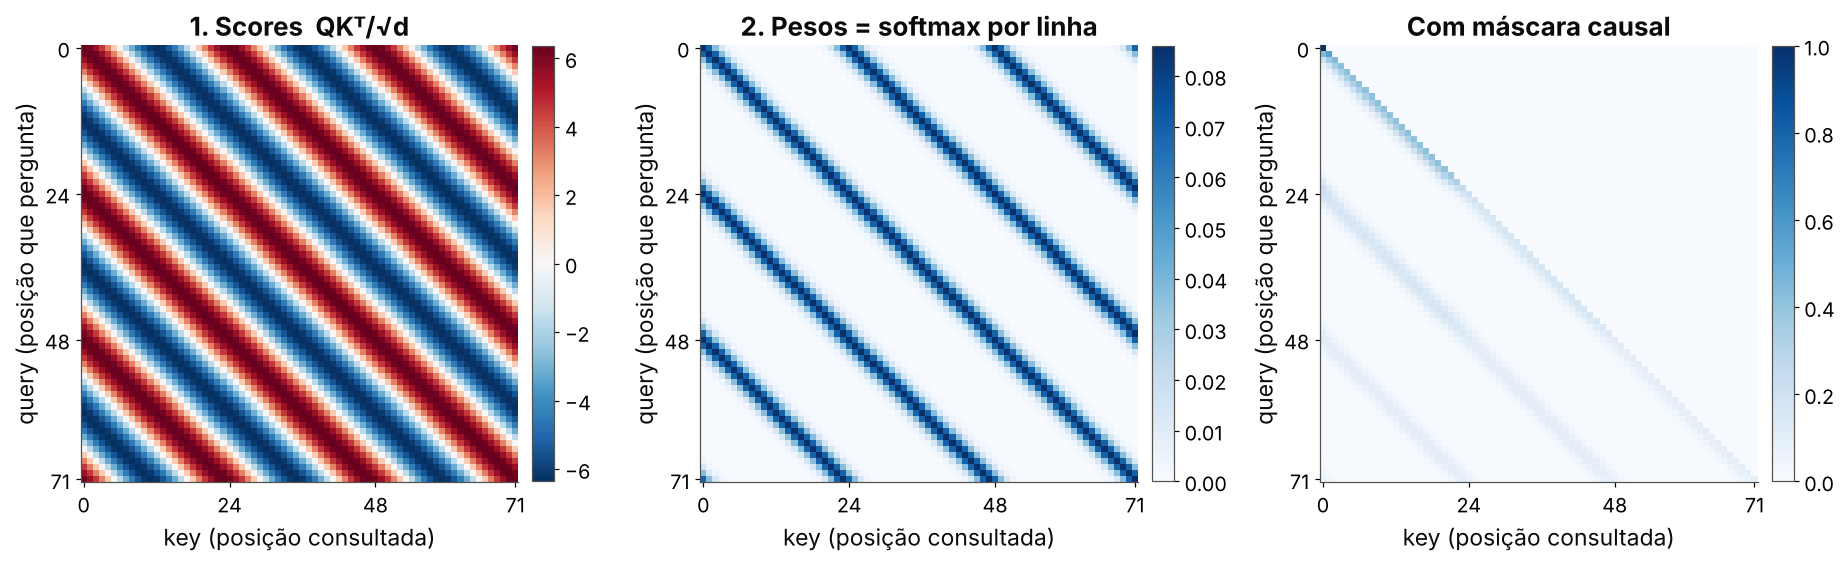

In [13]:
j0 = 24*35 + 5                                      # início de uma janela qualquer
horas = (np.arange(j0, j0+IN)) % 24
E = torch.tensor(np.stack([np.sin(2*np.pi*horas/24), np.cos(2*np.pi*horas/24)], 1), dtype=torch.float32)
Q = K = 3.0 * E                                     # "temperatura": quanto maior, mais seletiva
V = torch.tensor(y[j0:j0+IN], dtype=torch.float32).unsqueeze(-1)

saida, pesos = atencao(Q, K, V)
mascara_causal = torch.triu(torch.ones(IN, IN, dtype=torch.bool), diagonal=1)   # não ver o futuro
_, pesos_causal = atencao(Q, K, V, mascara_causal)

scores = (Q @ K.T / math.sqrt(2)).numpy()
fig, axs = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, M, tit, cmap in [(axs[0], scores, "1. Scores  QKᵀ/√d", "RdBu_r"),
                         (axs[1], pesos.numpy(), "2. Pesos = softmax por linha", "Blues"),
                         (axs[2], pesos_causal.numpy(), "Com máscara causal", "Blues")]:
    im = ax.imshow(M, cmap=cmap, aspect="equal", vmin=(-M.max() if cmap=="RdBu_r" else 0))
    ax.set_title(tit); ax.set_xlabel("key (posição consultada)"); ax.set_ylabel("query (posição que pergunta)")
    ax.set_xticks([0, 24, 48, 71]); ax.set_yticks([0, 24, 48, 71]); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
mostrar(fig, "09_self_attention_matrizes")

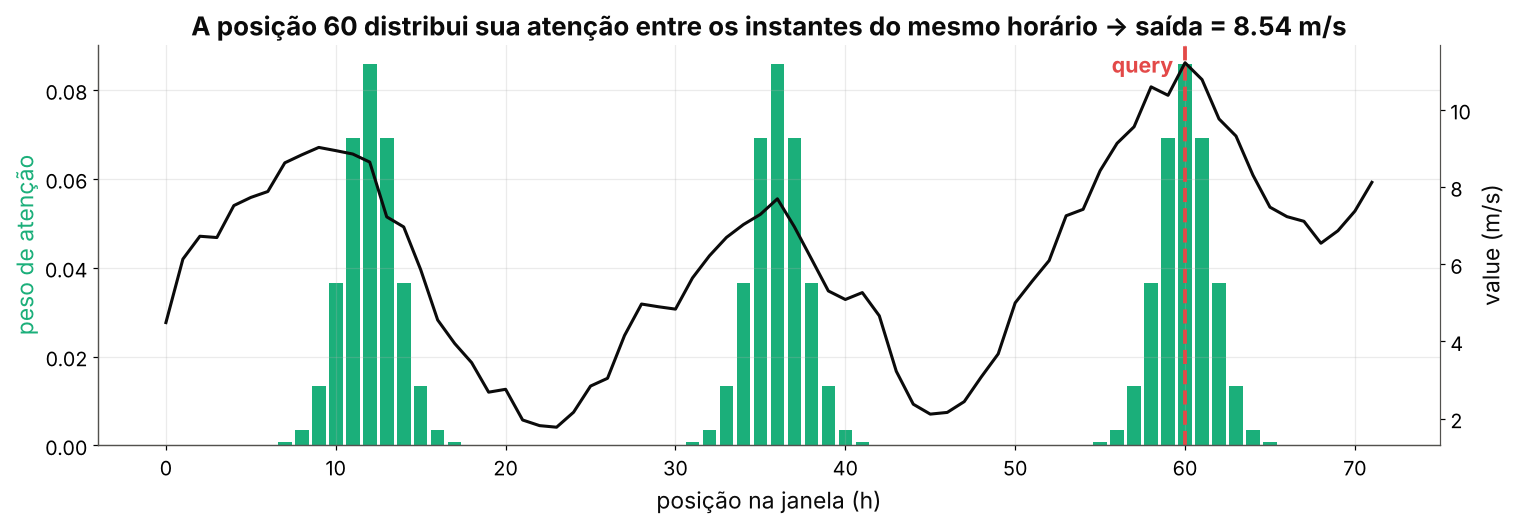

In [14]:
q = 60                                               # uma query específica
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(np.arange(IN), pesos[q].numpy(), color=COR["tf"], width=0.8, label="peso de atenção da posição 60")
ax1.set_ylabel("peso de atenção", color=COR["tf"]); ax1.set_xlabel("posição na janela (h)")
ax2 = ax1.twinx(); ax2.plot(np.arange(IN), V[:, 0].numpy(), color=COR["real"], lw=2, label="value (medição)")
ax2.set_ylabel("value (m/s)"); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax1.axvline(q, color=COR["destaque"], lw=2.5, ls="--"); ax1.text(q-0.7, ax1.get_ylim()[1]*0.93, "query", ha="right", color=COR["destaque"], fontsize=14, fontweight="bold")
ax1.set_title(f"A posição {q} distribui sua atenção entre os instantes do mesmo horário → saída = {saida[q,0]:.2f} m/s")
mostrar(fig, "10_self_attention_linha")

**Leitura:** a matriz de pesos mostra faixas a cada 24 posições: cada instante "consulta" principalmente os instantes no mesmo horário em outros dias, **em um único passo** — sem precisar propagar a informação por 24 passos recorrentes. A **máscara causal** (usada no decoder) zera os pesos para posições futuras: o triângulo superior fica vazio.

### 3B ▶️ Por que dividir por $\sqrt{d_k}$?

> 💡 **Analogia:** a nota $q\cdot k$ é uma soma de $d$ parcelas, como uma prova é a soma das questões: mais questões, notas maiores. Com notas enormes, o softmax vira **“o vencedor leva tudo”**. Dividir por $\sqrt{d_k}$ é **normalizar a nota**.

Se os componentes de $q$ e $k$ têm média 0 e variância 1, então $q\cdot k=\sum_{i=1}^{d_k} q_i k_i$ tem **variância $d_k$**. Com $d_k$ grande, os scores ficam enormes, o softmax **satura** (quase todo o peso vai para uma só posição) e os gradientes ficam próximos de zero. Dividir por $\sqrt{d_k}$ traz a variância de volta para 1.

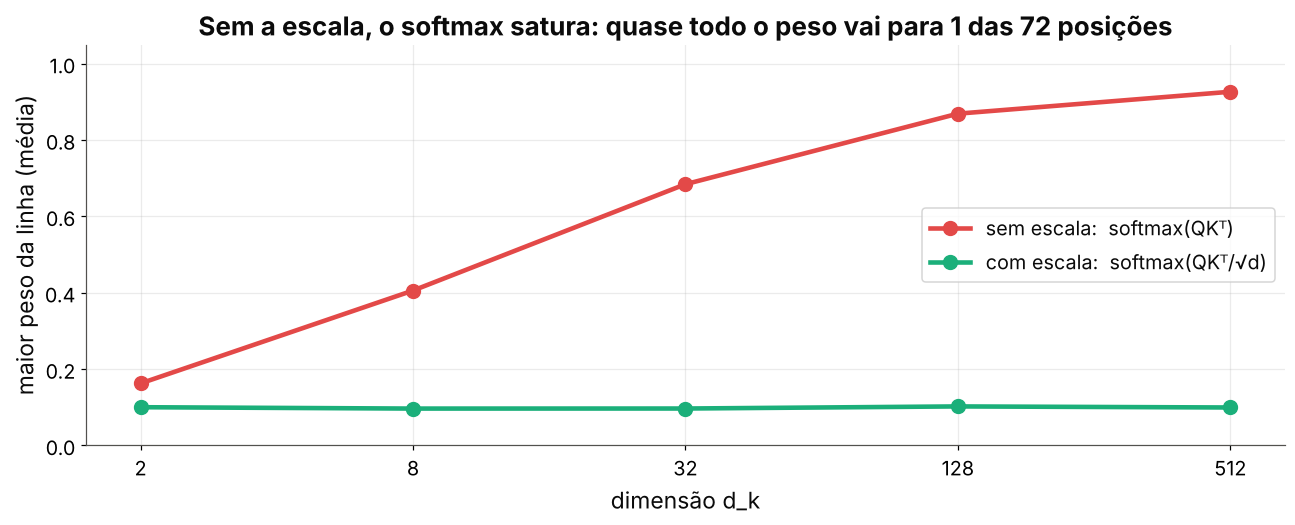

In [15]:
torch.manual_seed(0)
dims = [2, 8, 32, 128, 512]; n = 72
pico_sem, pico_com = [], []
for d in dims:
    q = torch.randn(500, 1, d); k = torch.randn(500, n, d)
    s = (q @ k.transpose(-2, -1)).squeeze(1)
    pico_sem.append(torch.softmax(s, -1).max(-1).values.mean().item())
    pico_com.append(torch.softmax(s / math.sqrt(d), -1).max(-1).values.mean().item())
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dims, pico_sem, "o-", color=COR["destaque"], lw=3, ms=9, label="sem escala:  softmax(QKᵀ)")
ax.plot(dims, pico_com, "o-", color=COR["tf"], lw=3, ms=9, label="com escala:  softmax(QKᵀ/√d)")
ax.set_xscale("log", base=2); ax.set_xticks(dims); ax.set_xticklabels(dims)
ax.set_xlabel("dimensão d_k"); ax.set_ylabel("maior peso da linha (média)")
ax.set_title(f"Sem a escala, o softmax satura: quase todo o peso vai para 1 das {n} posições")
ax.set_ylim(0, 1.05); ax.legend(loc="center right")
mostrar(fig, "11_escala_raiz_d")

### 3C ▶️ A atenção não sabe a ordem → codificação posicional

> 💡 **Analogia:** a atenção é como olhar um **álbum de fotos embaralhado**: vê bem o conteúdo, mas não a ordem. A codificação posicional **carimba cada foto** com sua posição, usando “ponteiros de relógio” que giram em velocidades diferentes.

A self-attention trata a entrada como um **conjunto**: se embaralharmos a sequência, as saídas são as mesmas, apenas embaralhadas (ela é *equivariante a permutações*). Para séries temporais isso é um problema — a ordem importa! Solução: **somar** à entrada um vetor que identifica a posição:

$$PE_{(p,\,2i)}=\sin\!\left(\frac{p}{10000^{2i/d}}\right),\qquad PE_{(p,\,2i+1)}=\cos\!\left(\frac{p}{10000^{2i/d}}\right)$$

Cada par de dimensões é uma senoide com frequência diferente — como os ponteiros de um relógio (segundos, minutos, horas…).

Embaralhar a entrada só embaralha a saída? True


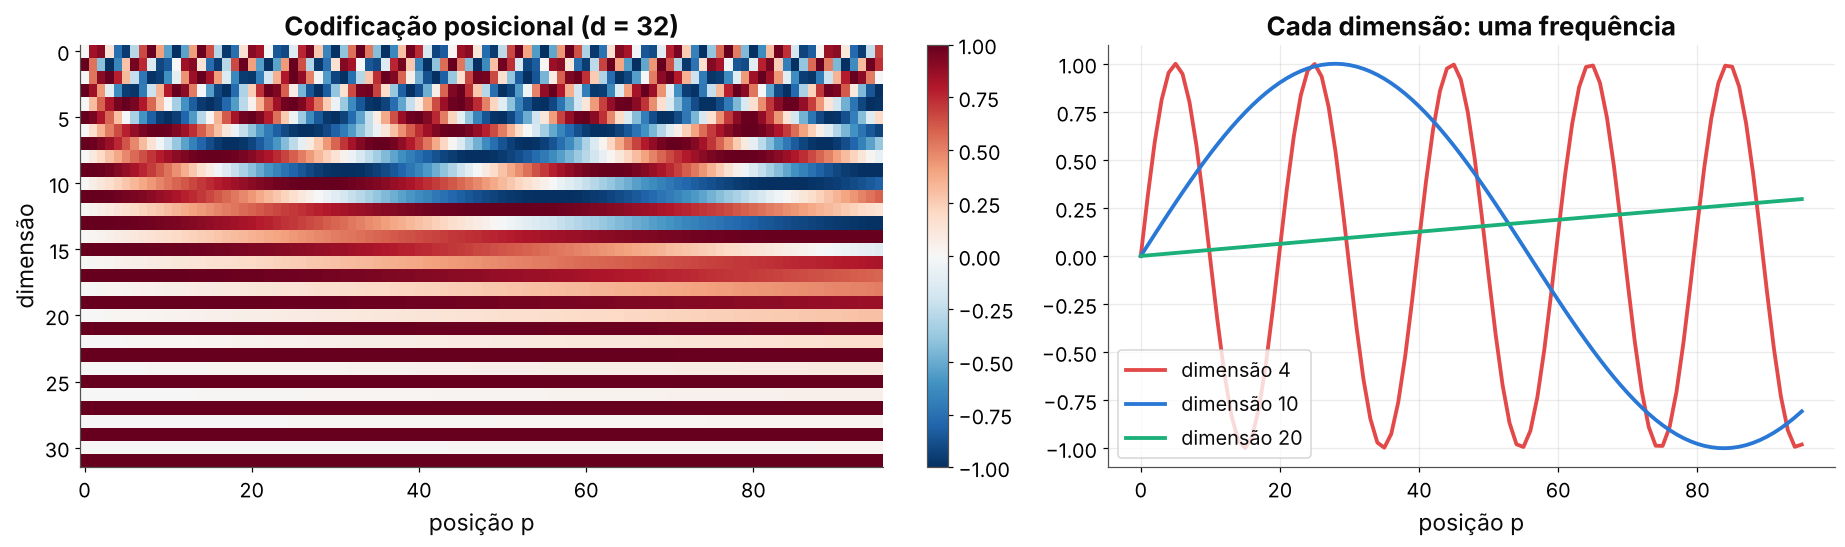

In [16]:
torch.manual_seed(0)
X = torch.randn(6, 4); Wq, Wk, Wv = (torch.randn(4, 4) for _ in range(3))
perm = torch.tensor([3, 0, 5, 1, 4, 2])
out, _      = atencao(X @ Wq, X @ Wk, X @ Wv)
out_perm, _ = atencao(X[perm] @ Wq, X[perm] @ Wk, X[perm] @ Wv)
print("Embaralhar a entrada só embaralha a saída?", torch.allclose(out[perm], out_perm, atol=1e-6))

def codificacao_posicional(T, d):
    p = torch.arange(T)[:, None]; i = torch.arange(0, d, 2)
    P = torch.zeros(T, d)
    P[:, 0::2] = torch.sin(p / 10000**(i/d)); P[:, 1::2] = torch.cos(p / 10000**(i/d))
    return P

PE = codificacao_posicional(96, 32)
fig, axs = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
im = axs[0].imshow(PE.T, cmap="RdBu_r", aspect="auto"); axs[0].grid(False)
axs[0].set_xlabel("posição p"); axs[0].set_ylabel("dimensão"); axs[0].set_title("Codificação posicional (d = 32)")
fig.colorbar(im, ax=axs[0], fraction=0.03)
for dim, cor in [(4, COR["destaque"]), (10, COR["lstm"]), (20, COR["tf"])]:
    axs[1].plot(PE[:, dim], color=cor, lw=2.5, label=f"dimensão {dim}")
axs[1].set_xlabel("posição p"); axs[1].set_title("Cada dimensão: uma frequência"); axs[1].legend(loc="lower left")
mostrar(fig, "12_codificacao_posicional")

#### ▶️ Lendo o gráfico: cada linha é um relógio

Para enxergar a ideia, usamos um carimbo pequeno, com $d = 8$ números, ou seja, **4 relógios** (cada um é um par seno/cosseno).

* **Por que não numerar 0, 1, 2…?** O número da posição cresceria até 71 e abafaria o dado (vento de 8 m/s).
* **Por que não um relógio só?** Ele se repete: a posição 0 e a posição 24 ganhariam o mesmo carimbo.
* **Por que seno *e* cosseno?** A posição de um ponteiro é descrita por dois números (altura e lado); só a altura confundiria um ponteiro subindo com um descendo.
* **O carimbo de uma posição** é uma *coluna* do mapa à direita: 8 números, **somados** ao vetor daquela hora.

À esquerda, cada linha colorida mostra onde está o ponteiro de um relógio em cada posição; os pontos marcam as posições 10 e 40. O relógio rápido sozinho poderia confundi-las, mas a **combinação** dos quatro é única.

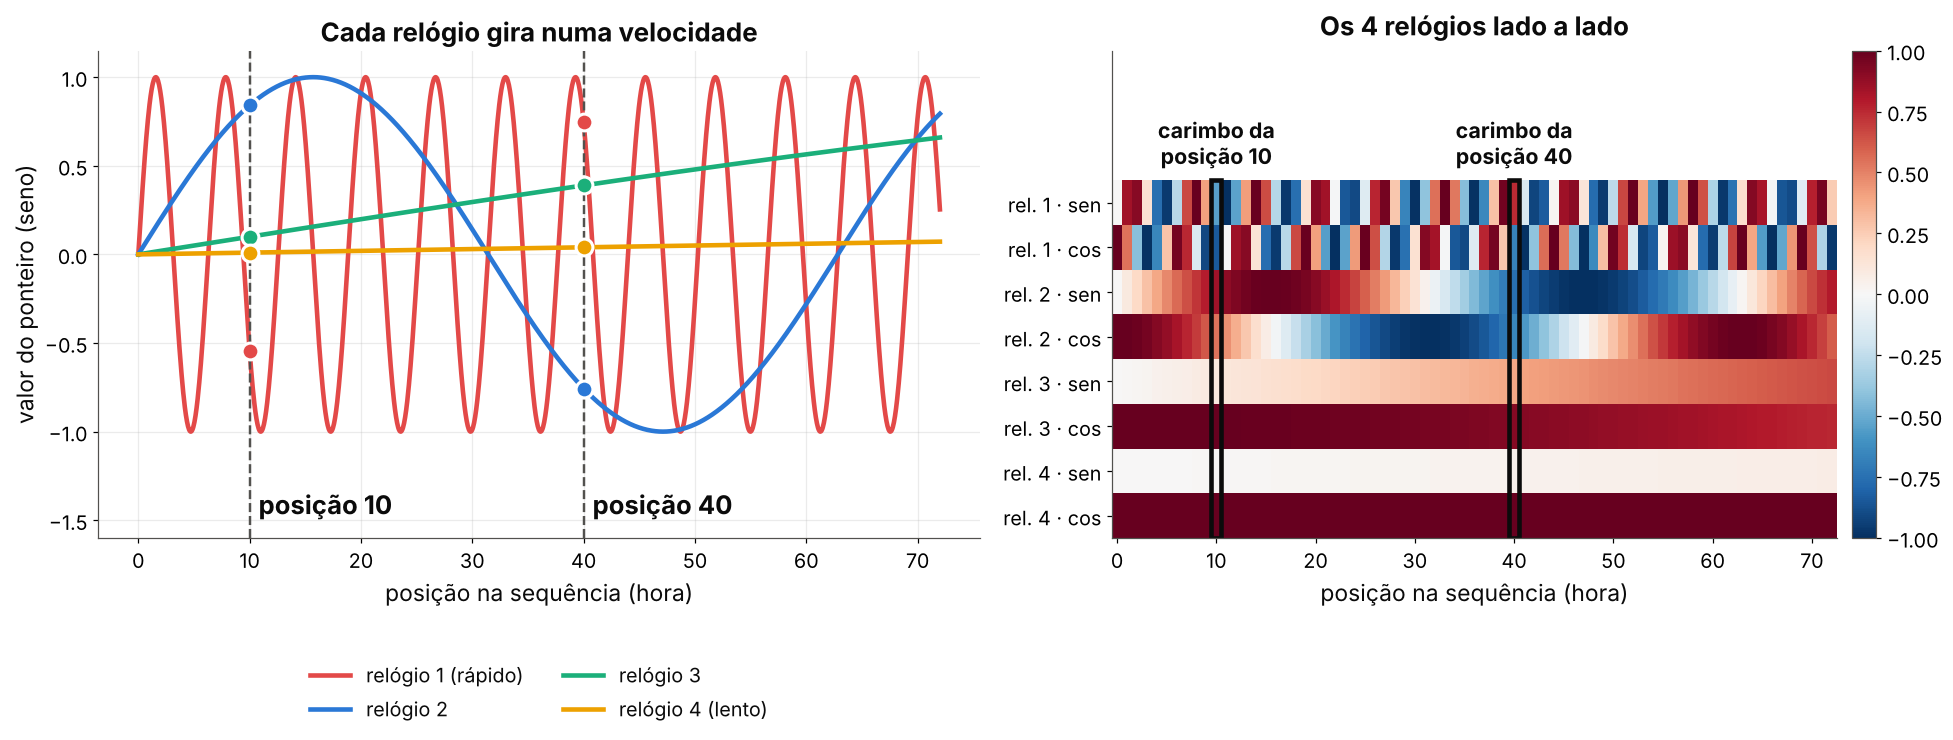

carimbo(10) = [-0.54 -0.84  0.84  0.54  0.1   1.    0.01  1.  ]
carimbo(40) = [ 0.75 -0.67 -0.76 -0.65  0.39  0.92  0.04  1.  ]


In [17]:
# Codificação posicional "de brinquedo": d = 8 → 4 relógios (cada um = par seno/cosseno)
d_pe, T_pe = 8, 73
PE8 = codificacao_posicional(T_pe, d_pe).numpy()          # (posição, dimensão)
p1, p2 = 10, 40                                           # duas posições para comparar
cores_rel = [COR["destaque"], COR["lstm"], COR["tf"], COR["saz"]]
nomes_rel = ["relógio 1 (rápido)", "relógio 2", "relógio 3", "relógio 4 (lento)"]

fig, axs = plt.subplots(1, 2, figsize=(18, 7.2), gridspec_kw={"width_ratios": [1.15, 1]})
# (a) cada relógio = uma onda ao longo das posições
xf = np.linspace(0, T_pe - 1, 1500)                       # curva contínua (o ponteiro gira suavemente)
for r in range(4):
    w = 1 / 10000**(2*r/d_pe)
    axs[0].plot(xf, np.sin(xf * w), color=cores_rel[r], lw=3, label=nomes_rel[r])
for p in (p1, p2):
    axs[0].axvline(p, color="#52514e", ls="--", lw=1.6)
    for r in range(4):
        axs[0].plot(p, PE8[p, 2*r], "o", ms=11, color=cores_rel[r], mec="white", mew=2)
    axs[0].text(p + 0.8, -1.5, f"posição {p}", fontsize="large", fontweight="bold", color="#0b0b0b", va="bottom")
axs[0].set_ylim(-1.6, 1.15); axs[0].set_xlabel("posição na sequência (hora)"); axs[0].set_ylabel("valor do ponteiro (seno)")
axs[0].set_title("Cada relógio gira numa velocidade"); axs[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
# (b) o carimbo de cada posição = uma coluna do mapa
im = axs[1].imshow(PE8.T, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto"); axs[1].grid(False)
for p in (p1, p2):
    axs[1].add_patch(Rectangle((p - 0.5, -0.5), 1, d_pe, fill=False, ec="#0b0b0b", lw=3))
    axs[1].text(p, -0.75, f"carimbo da\nposição {p}", ha="center", va="bottom", fontsize="medium", fontweight="bold")
axs[1].set_yticks(range(d_pe)); axs[1].set_yticklabels([f"rel. {i//2+1} · {'sen' if i%2==0 else 'cos'}" for i in range(d_pe)])
axs[1].set_xlabel("posição na sequência (hora)"); axs[1].set_ylim(d_pe - 0.5, -3.4)
axs[1].set_title("Os 4 relógios lado a lado", pad=10)
fig.colorbar(im, ax=axs[1], fraction=0.035, pad=0.02)
mostrar(fig, "15_relogios_posicionais")
print(f"carimbo({p1}) =", np.round(PE8[p1], 2)); print(f"carimbo({p2}) =", np.round(PE8[p2], 2))


### 3D. Um Transformer encoder-decoder pequeno para previsão

> 💡 **Analogia:** **multi-cabeça** = vários especialistas olhando a mesma série (um olha a última hora, outro o mesmo horário de ontem); **conexão residual** = um atalho por onde a informação original sempre passa; **máscara causal** = proibido espiar o futuro.

Montamos o Transformer **com a mesma função `atencao`** escrita acima:

* **Encoder:** cada hora de entrada vira um vetor ($d=32$) + codificação posicional → *self-attention* multi-cabeça → FFN, com conexões residuais e LayerNorm.
* **Decoder:** 24 vetores de consulta (um por hora futura, também com codificação posicional) fazem **cross-attention** sobre a saída do encoder: *"quais horas do passado importam para prever a hora k?"*.
* As 24 horas são previstas **de uma vez** (não autorregressivo) — sem acúmulo de erros e totalmente paralelo.

**Multi-head:** em vez de uma única atenção com $d=32$, usamos $h=2$ cabeças com $d=16$ cada, que podem aprender padrões diferentes; as saídas são concatenadas.

In [18]:
class AtencaoMultiCabeca(nn.Module):
    def __init__(self, d, cabecas):
        super().__init__()
        self.h = cabecas
        self.Wq, self.Wk, self.Wv, self.Wo = (nn.Linear(d, d) for _ in range(4))
    def forward(self, x_q, x_kv):
        B, nq, d = x_q.shape; nk = x_kv.shape[1]
        separa = lambda z, n: z.view(B, n, self.h, d // self.h).transpose(1, 2)   # (B, h, n, d/h)
        saida, pesos = atencao(separa(self.Wq(x_q), nq), separa(self.Wk(x_kv), nk), separa(self.Wv(x_kv), nk))
        return self.Wo(saida.transpose(1, 2).reshape(B, nq, d)), pesos

class BlocoTransformer(nn.Module):
    def __init__(self, d, cabecas):
        super().__init__()
        self.att = AtencaoMultiCabeca(d, cabecas); self.norm1 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 2*d), nn.GELU(), nn.Linear(2*d, d)); self.norm2 = nn.LayerNorm(d)
    def forward(self, x, memoria=None):
        a, pesos = self.att(x, x if memoria is None else memoria)   # self- ou cross-attention
        x = self.norm1(x + a)                                     # residual + LayerNorm
        return self.norm2(x + self.ffn(x)), pesos

class TransformerPrevisao(nn.Module):
    def __init__(self, d=32, cabecas=2):
        super().__init__()
        self.embed = nn.Linear(1, d)
        self.register_buffer("PE", codificacao_posicional(IN + OUT, d))
        self.encoder = BlocoTransformer(d, cabecas)
        self.consultas = nn.Parameter(torch.zeros(OUT, d))           # uma query aprendida por hora futura
        self.decoder = BlocoTransformer(d, cabecas)
        self.saida = nn.Linear(d, 1)
    def forward(self, x):
        B = x.shape[0]
        mem, pesos_enc = self.encoder(self.embed(x.unsqueeze(-1)) + self.PE[:IN])
        q = (self.consultas + self.PE[IN:]).expand(B, -1, -1)
        h, pesos_cross = self.decoder(q, memoria=mem)
        return self.saida(h).squeeze(-1), pesos_enc, pesos_cross

torch.manual_seed(0); tfm = TransformerPrevisao()
print(f"Parâmetros: Transformer {n_par(tfm):,}  |  Seq2Seq LSTM {n_par(s2s):,}".replace(",", "."))
tfm = treinar(tfm, epocas=10)

Parâmetros: Transformer 17.953  |  Seq2Seq LSTM 34.369


TransformerPrevisao: 10 épocas em 12 s


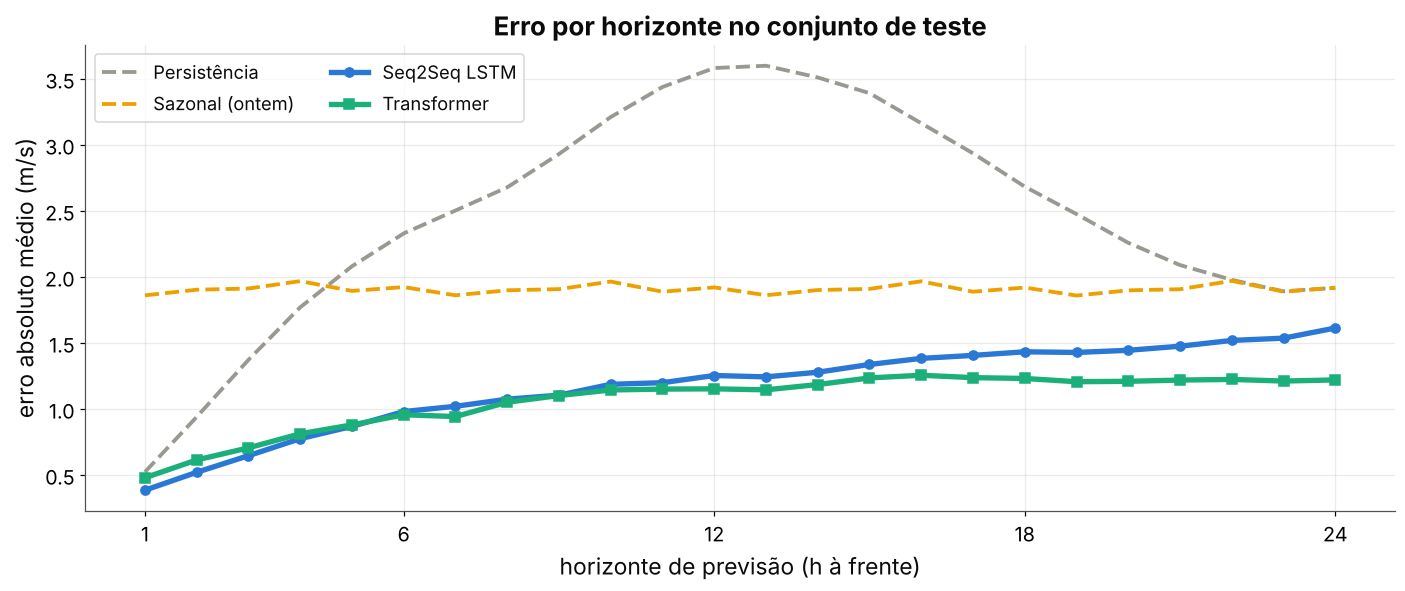

Persistência   MAE médio = 2.47 m/s
Sazonal        MAE médio = 1.91 m/s
Seq2Seq LSTM   MAE médio = 1.17 m/s
Transformer    MAE médio = 1.06 m/s


In [19]:
with torch.no_grad(): P_tf, A_enc, A_cross = tfm(Xte)

fig, ax = plt.subplots(figsize=(13, 5.6))
ax.plot(h, mae_h(P_pers), color=COR["pers"], lw=2.5, ls="--", label="Persistência")
ax.plot(h, mae_h(P_saz),  color=COR["saz"],  lw=2.5, ls="--", label="Sazonal (ontem)")
ax.plot(h, mae_h(P_s2s),  color=COR["s2s"],  lw=3.5, marker="o", ms=6, label="Seq2Seq LSTM")
ax.plot(h, mae_h(P_tf),   color=COR["tf"],   lw=3.5, marker="s", ms=6, label="Transformer")
ax.set_xlabel("horizonte de previsão (h à frente)"); ax.set_ylabel("erro absoluto médio (m/s)")
ax.set_title("Erro por horizonte no conjunto de teste"); ax.set_xticks([1, 6, 12, 18, 24])
ax.legend(loc="upper left", fontsize=12, ncol=2)
mostrar(fig, "13_comparacao_mae")
for nome, P in [("Persistência", P_pers), ("Sazonal", P_saz), ("Seq2Seq LSTM", P_s2s), ("Transformer", P_tf)]:
    print(f"{nome:14s} MAE médio = {mae_h(P).mean():.2f} m/s")

### 3E ▶️ Para onde o Transformer olha?

A **cross-attention** dá, para cada hora futura (linha), os pesos sobre as 72 horas de entrada (colunas). Média sobre todas as janelas de teste e cabeças.

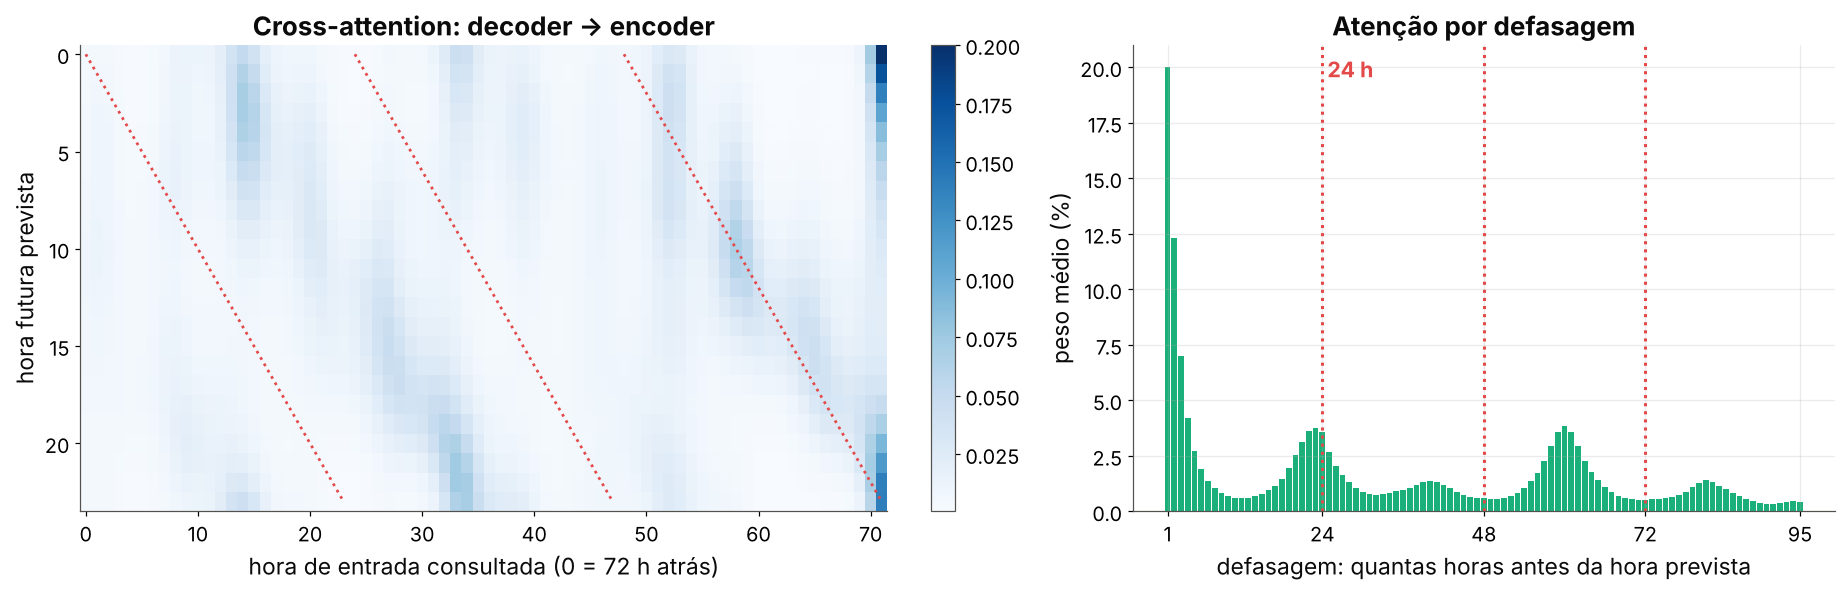

In [20]:
Ac = A_cross.mean(dim=(0, 1)).numpy()                 # (24 horas futuras × 72 horas de entrada)
# perfil por defasagem: distância (em horas) entre a hora prevista e a hora consultada
perfil = np.zeros(IN + OUT); cont = np.zeros(IN + OUT)
for k in range(OUT):
    for j in range(IN):
        lag = IN + k - j; perfil[lag] += Ac[k, j]; cont[lag] += 1
perfil = perfil / np.maximum(cont, 1)

fig, axs = plt.subplots(1, 2, figsize=(17, 5.6), gridspec_kw={"width_ratios": [1.25, 1]})
im = axs[0].imshow(Ac, cmap="Blues", aspect="auto"); axs[0].grid(False)
for off in [0, 24, 48]:                                # mesma hora em dias anteriores
    axs[0].plot(np.arange(OUT) + off, np.arange(OUT), color=COR["destaque"], ls=":", lw=1.8)
axs[0].set_xlabel("hora de entrada consultada (0 = 72 h atrás)"); axs[0].set_ylabel("hora futura prevista")
axs[0].set_title("Cross-attention: decoder → encoder"); fig.colorbar(im, ax=axs[0], fraction=0.03)
lags = np.arange(1, IN + OUT)
axs[1].bar(lags, perfil[1:] * 100, color=COR["tf"], width=0.85)
for L_ in [24, 48, 72]: axs[1].axvline(L_, color=COR["destaque"], ls=":", lw=2)
axs[1].text(24, axs[1].get_ylim()[1]*0.93, " 24 h", color=COR["destaque"], fontsize=14, fontweight="bold")
axs[1].set_xlabel("defasagem: quantas horas antes da hora prevista"); axs[1].set_ylabel("peso médio (%)")
axs[1].set_title("Atenção por defasagem"); axs[1].set_xticks([1, 24, 48, 72, 95])
mostrar(fig, "14_cross_attention")

**Leitura:** as linhas pontilhadas marcam "a mesma hora, 1, 2 e 3 dias antes". O modelo concentra a atenção no **passado recente** (defasagem 1–3 h) e em torno de **24 h** — ele descobriu sozinho o ciclo diário que colocamos na série, e consulta esses instantes **diretamente**, sem gargalo.

**Cuidado ao interpretar:** há também um pico em torno de 60 h que não tem explicação óbvia. Os pesos de atenção são uma *pista* sobre o que o modelo usa, não uma explicação completa (veja Jain & Wallace, 2019, *Attention is not Explanation*).

---
## 5. Resumo

| | RNN / LSTM | Encoder-Decoder (Seq2Seq) | Transformer |
|---|---|---|---|
| Analogia | leitor com caderno | meteorologista com post-it | reunião: todos falam com todos |
| Ideia | estado oculto que carrega memória | comprimir a entrada e gerar a saída | atenção: cada posição consulta todas as outras |
| Dependências longas | difícil (RNN) / melhor (LSTM) | limitado pelo vetor de contexto | caminho direto (1 passo) |
| Paralelismo no treino | sequencial | sequencial | total |
| Custo em relação ao comprimento $n$ | $O(n)$ | $O(n)$ | $O(n^2)$ |
| Quando brilha | séries com poucos dados, *streaming* | entradas/saídas de tamanhos diferentes | muitos dados, contexto longo, escala |

**Referências:** Hochreiter & Schmidhuber (1997) — LSTM · Cho et al. (2014); Sutskever et al. (2014) — Seq2Seq · Bahdanau et al. (2015) — atenção · Vaswani et al. (2017) — *Attention Is All You Need* · Jozefowicz et al. (2015) — bias da porta de esquecimento.